In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.models import Sequential
from nltk.translate.bleu_score import sentence_bleu

In [ ]:
text ="""Shall I compare thee to a summer's day? Thou art more lovely and more
temperate."""
# Create character mapping
chars = sorted(set(text)) # Unique characters
char_to_index = {char: i for i, char in enumerate(chars)}
index_to_char = {i: char for i, char in enumerate(chars)}
# Convert text to sequences
sequences = []
for i in range(len(text) - 5): # Create sequences of length 5
 seq = text[i:i+5]
 sequences.append([char_to_index[char] for char in seq])
X = np.array([seq[:-1] for seq in sequences]) # Inputs
y = np.array([seq[-1] for seq in sequences]) # Targets
# One-hot encode the target variable
y = tf.keras.utils.to_categorical(y, num_classes=len(chars))

In [ ]:
model = Sequential([
 Embedding(input_dim=len(chars), output_dim=8, input_length=4),
 LSTM(64, return_sequences=False),
 Dense(len(chars), activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 151ms/step - accuracy: 0.1667 - loss: 3.1758 - val_accuracy: 0.0667 - val_loss: 3.1716
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.2000 - loss: 3.1683 - val_accuracy: 0.0667 - val_loss: 3.1652
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2000 - loss: 3.1610 - val_accuracy: 0.0667 - val_loss: 3.1585
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2000 - loss: 3.1530 - val_accuracy: 0.0667 - val_loss: 3.1502
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2000 - loss: 3.1431 - val_accuracy: 0.0667 - val_loss: 3.1409
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2000 - loss: 3.1309 - val_accuracy: 0.0667 - val_loss: 3.1291
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2000 - loss: 3.1151 - val_accuracy: 0.0667 - val_loss: 3.1134
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.2000 - loss: 3.0955 - val_accuracy: 0.0667 - val_loss: 3.0931

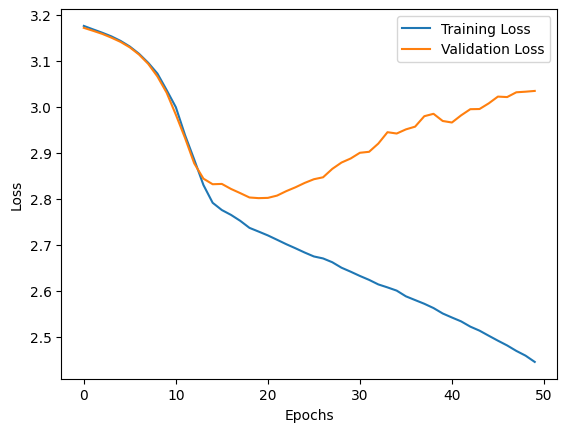

In [ ]:
history = model.fit(X, y, batch_size=16, epochs=50, validation_split=0.2)
# Plot Training Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
def generate_text(seed_text, length=40):
 generated = seed_text
 for _ in range(length):
  seq = [char_to_index[char] for char in generated[-4:]] # Last 4 characters
  seq = np.array(seq).reshape(1, -1)
  pred_index = np.argmax(model.predict(seq))
  next_char = index_to_char[pred_index]
  generated += next_char
 return generated

In [ ]:
def calculate_perplexity(loss):
 return np.exp(loss)
final_loss = history.history['loss'][-1]
perplexity = calculate_perplexity(final_loss)
print(f"Perplexity: {perplexity:.2f}")

Perplexity: 11.53


In [ ]:
reference_text = list("Shall I compare thee to a summer's day?")
generated_text = list(generate_text("Shall I compare thee to a summer's day?",
length=len(reference_text)))
bleu_score = sentence_bleu([reference_text], generated_text)
print(f"BLEU Score: {bleu_score:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━

In [ ]:
def character_accuracy(reference, generated):
 correct = sum(1 for a, b in zip(reference, generated) if a == b)
 return correct / len(reference)
accuracy = character_accuracy(reference_text, generated_text)
print(f"Character-Level Accuracy: {accuracy:.2%}")

Character-Level Accuracy: 100.00%


In [ ]:
seed = "Shall I compare thee to a summer's day?"
generated_text = generate_text(seed, length=50)
print("\nGenerated Text:\n", generated_text)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━